In [1]:
from multistability import *

/home/nitesh/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# 1

## a)

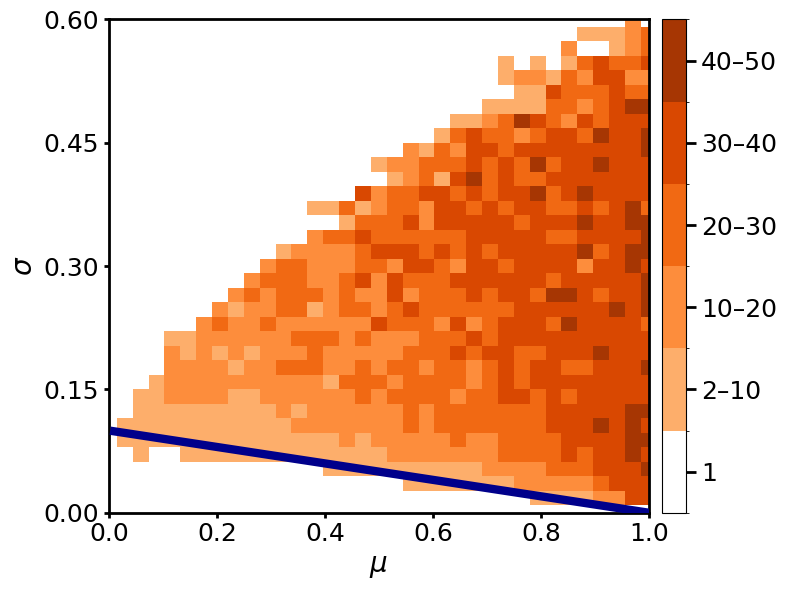

In [2]:
# Load data
data = np.load('likelihood_data/phase_data.npz')
mu = data['mu']
si = data['si']
phase = data['phase']

# Set up grid
fig, ax = plt.subplots(figsize=(8, 6))
X, Y = np.meshgrid(mu, si[:phase.shape[0]])

# Colormap settings
bounds = [1, 2, 10, 20, 30, 40, 50]
colors = ['white', '#fdae6b', '#fd8d3c', '#f16913', '#d94801', '#a63603']
cmap = ListedColormap(colors)
norm = BoundaryNorm(bounds, ncolors=len(colors), clip=True)

# Plot data
pcm = ax.pcolormesh(X, Y, phase, cmap=cmap, norm=norm, shading='nearest')

#phase boundary
x = np.linspace(0.01, 1, 200)
y = np.sqrt(1/100) * (1 - x)
ax.plot(x, y, c='darkblue', linewidth=6, zorder=10)

# Labels and axes
ax.set_xlabel(r'$\mu$', fontsize=20)
ax.set_ylabel(r'$\sigma$', fontsize=20)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.15))
ax.tick_params(labelsize=18, width=2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.6)

for spine in ax.spines.values():
    spine.set_linewidth(2)

# Colorbar
tick_locs = [1.5, (2+10)/2, (10+20)/2, (20+30)/2, (30+40)/2, (40+50)/2]
tick_labels = ['1','2–10','10–20','20–30','30–40','40–50']
cbar = fig.colorbar(pcm, ax=ax, ticks=tick_locs, pad=0.02)
cbar.ax.set_yticklabels(tick_labels, fontsize=18)
cbar.ax.tick_params(labelsize=18, length=7, width=2)

plt.tight_layout()
plt.show()


## c)1)

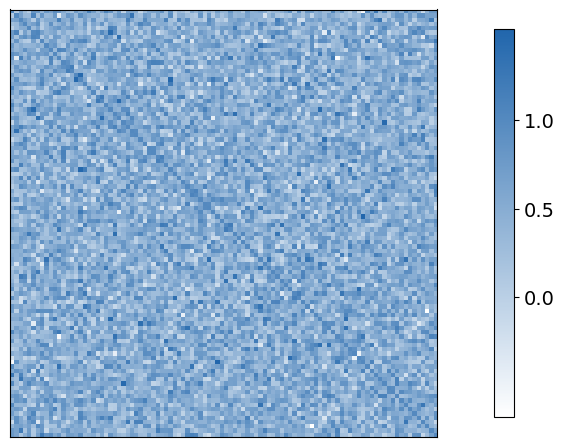

In [3]:
# Load matrix
with open("likelihood_data/mat_1_100.pkl", "rb") as f:
    A = pickle.load(f)

# Colormap
colors = ["white", "#2166ac"]
cmap = LinearSegmentedColormap.from_list("white_to_blue", colors)

# Plot matrix
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(A, cmap=cmap)

ax.set_xticks([])
ax.set_yticks([])

# Colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.1, shrink=0.68)
cbar.ax.tick_params(labelsize=14)
cbar.set_ticks([0, 0.5, 1])

# Save figure
plt.tight_layout()
plt.savefig('1_a_1.svg', dpi=300)
plt.show()


## c)2)

In [4]:
with open("likelihood_data/data_fig1c_2.dat", "rb") as f:
    data = np.load(f)

    biomass = data["biomass"]
    basin = data["basin"]
    centers_bio = data["centers_bio"]
    obs_mean_curve = data["obs_mean_curve"]
    fit_mean_curve = data["fit_mean_curve"]

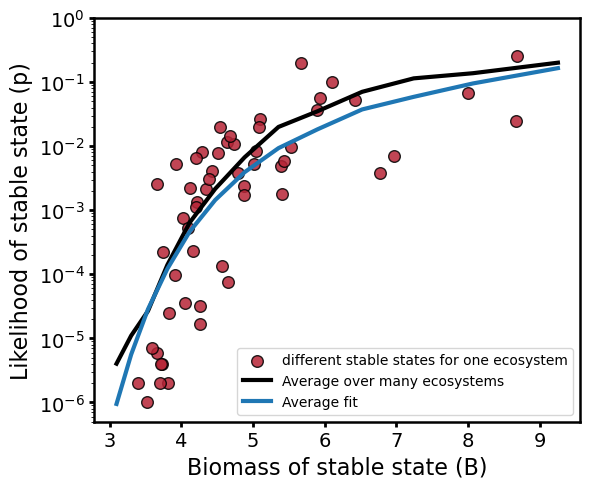

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    biomass, basin,
    color='#b62436fd',
    edgecolor='k',
    s=70,
    alpha=0.85,
    zorder=2,
    label='different stable states for one ecosystem'
)

ax.plot(
    centers_bio, obs_mean_curve,
    color='black',
    linewidth=3,
    label='Average over many ecosystems'
)

ax.plot(
    centers_bio, fit_mean_curve,
    linewidth=3,
    label='Average fit'
)

ax.set_yscale('log')
ax.set_xlabel('Biomass of stable state (B)', fontsize=16)
ax.set_ylabel('Likelihood of stable state (p)', fontsize=16)

ax.tick_params(labelsize=14, width=2)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

plt.ylim(0.5e-6, 1)
plt.tight_layout()
plt.legend()
plt.show()

# 2)

## a)

In [6]:
# Surviving species sets for each unique state
with open("likelihood_data/data_fig2a.pkl", "rb") as f:
    group1 = pickle.load(f)

# Selected (i, j) pairs from co-occurring survivors (i < j)
selected_pairs = set()
for group in group1:
    group_sorted = sorted(group)
    for i, j in itertools.combinations(group_sorted, 2):
        selected_pairs.add((i, j))

# Values for selected pairs
result_array = np.array([A[i][j] for (i, j) in selected_pairs])

# -------------------------------------------------------
# Complement: all other upper-triangle pairs (i < j)
N = A.shape[0]
all_upper_pairs = {(i, j) for i in range(N) for j in range(i+1, N)}
other_pairs = all_upper_pairs - selected_pairs

# Values for complement pairs
other_result_array = np.array([A[i][j] for (i, j) in other_pairs])


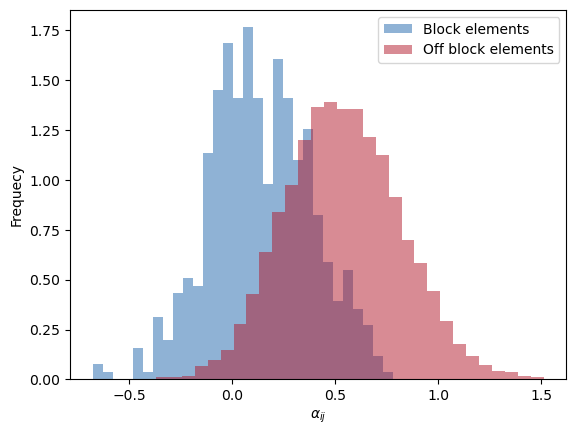

In [7]:
plt.hist(result_array, density=True, alpha=0.5, label='Block elements',bins = 30,color = "#2166ac")
plt.hist(other_result_array, density=True, alpha=0.5, label='Off block elements',bins = 30,color = "#b2182b")
plt.legend()
plt.xlabel(r'$\alpha_{ij}$')
plt.ylabel('Frequecy')
plt.show()

## c)

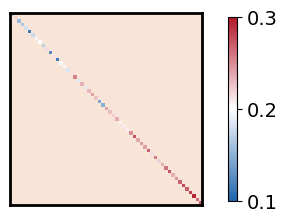

In [8]:
# effective self inhibition
si = 1 / biomass

# matrix for effective species
A_s = 0.5 * np.ones((len(si), len(si)))
for i in range(len(si)):
    A_s[i, i] = si[i]

# colormap anchors
vmin_diag = 0.1
vmid_diag = 0.2
vmax_diag = 0.3
pos1 = 0.0
pos2 = (vmid_diag - vmin_diag) / (vmax_diag - vmin_diag)
pos3 = 1.0

colors = [
    (pos1, "#2166ac"),
    (pos2, "white"),
    (pos3, "#b2182b"),
]
cmap_custom = LinearSegmentedColormap.from_list("custom_bwr", colors)

# masks
n = A_s.shape[0]
diag_mask = np.eye(n, dtype=bool)
off_diag_array = np.ones_like(A_s)
off_diag_masked = np.ma.masked_where(diag_mask, off_diag_array)
diag_masked = np.ma.masked_where(~diag_mask, A_s)

# plot
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(off_diag_masked, cmap=ListedColormap(['#f9e5d8']), vmin=0, vmax=1)
im = ax.imshow(diag_masked, cmap=cmap_custom, vmin=vmin_diag, vmax=vmax_diag)

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(2)

# colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.1, shrink=0.68)
cbar.ax.tick_params(labelsize=14)
cbar.set_ticks([0.1, 0.2, 0.3])
cbar.set_ticklabels(["0.1", "0.2", "0.3"])

plt.tight_layout()
plt.show()


## d)

### monodominant model with 10 species

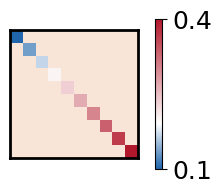

In [9]:
# Load matrix of monodominant model with 10 species
k = 10
file_path_unique = f'likelihood_data/mat_2_mono_10.pkl'
with open(file_path_unique, 'rb') as file:
    A = pickle.load(file)

# Colormap for diagonal
cmap = LinearSegmentedColormap.from_list(
    "blue_white_red",
    [
        (0.00, "#2166ac"),
        (0.3, "white"),
        (1.00, "#b2182b")
    ]
)

# Plot diagonal (off-diagonals shown with fixed color)
fig, ax = plt.subplots(figsize=(2.5, 2.5))

A_diag_only = np.full_like(A, np.nan)
np.fill_diagonal(A_diag_only, np.diag(A))
im = ax.imshow(A_diag_only, cmap=cmap, vmin=0.1, vmax=0.4, zorder=1)

off_diag_mask = ~np.eye(A.shape[0], dtype=bool)
off_diag_overlay = np.full_like(A, np.nan, dtype=float)
off_diag_overlay[off_diag_mask] = 1

peach_cmap = LinearSegmentedColormap.from_list("offdiag", ['#f9e5d8', '#f9e5d8'])
ax.imshow(off_diag_overlay, cmap=peach_cmap, vmin=0, vmax=1, zorder=0)

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(2)

# Colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.1, shrink=0.68)
cbar.ax.tick_params(labelsize=18)
cbar.set_ticks([0.1, 0.4])

plt.subplots_adjust(right=0.3)
plt.tight_layout()

plt.show()

In [10]:
with open("likelihood_data/data_fig2d_2.dat", "r") as f:
    lines = f.readlines()

k = int(lines[0].strip())                    # first line
biomass = np.fromstring(lines[1], sep=' ')   # second line
basin = np.fromstring(lines[2], sep=' ')     # third line
num_list = np.fromstring(lines[3], sep=' ')  # fourth line


## Main paper equation 4 (preediction of likelihood using biomass)


In [11]:
def likelihood_monodominant(biomass, basin, num_list, X):
    """
    Compute monodominant likelihoods given biomass, basin sizes, and X.
    
    Parameters
    ----------
    biomass : array-like
        Biomass of each unique state.
    basin : array-like
        Basin sizes (likelihoods) of each unique state.
    num_list : array-like
        Number of survivors per unique state.
    X : float or array-like
        Threshold/parameter for chi computation.
    
    Returns
    -------
    probabilities : np.ndarray
        Probability for each state.
    biomass_sorted : np.ndarray
        Biomass values sorted according to chi.
    """
    
    biomass = np.array(biomass, dtype=float)
    basin = np.array(basin, dtype=float)
    
    # Effective a_i and χ_i
    a_list = 1 / biomass
    chi = X - a_list
    chi = np.array(chi, dtype=float)

    # Sort by chi
    idx = np.argsort(chi)
    chi_sorted = chi[idx]
    biomass_sorted = biomass[idx]

    # Compute probabilities
    def compute_p(chi_list):
        chi = np.asarray(chi_list, dtype=float)
        S = len(chi)

        chi_ext = np.concatenate(([0.0], chi))

        suffix_prod = np.ones(S + 1)
        running = 1.0
        for j in range(S, 0, -1):
            running *= chi_ext[j]
            suffix_prod[j] = running

        p = np.zeros(S)
        for i in range(1, S + 1):
            val = 0.0
            for k in range(1, i + 1):
                power = S - k + 1
                num = chi_ext[k]**power - chi_ext[k - 1]**power
                den = power * suffix_prod[k]
                val += num / den
            p[i - 1] = val
        return p

    probabilities = compute_p(chi_sorted)
    return probabilities, biomass_sorted

In [12]:
#calculate probability using biomass from monodominant model theory
probabilities,biomass_1 = likelihood_monodominant(biomass,basin,num_list,1)

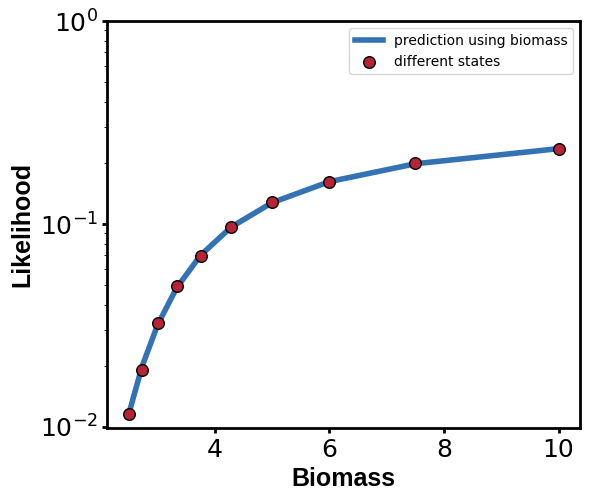

In [13]:
# Global font settings


# -----------------------------
# Styled Plot (no fitting)
fig, ax = plt.subplots(figsize=(6, 5))

# Line plot of sorted(biomass) vs sorted(probabilities)
ax.plot(biomass_1, probabilities, color='#3372b3ff', linewidth=4, zorder=1,label='prediction using biomass')

# Scatter plot of biomass vs basin
ax.scatter(biomass, basin, color='#b62436fd', edgecolor='k', alpha=1, zorder=2, s=70,label='different states')

# Log scale for y-axis
ax.set_yscale('log')

# Horizontal reference line at y = 1
# ax.axhline(y=1, color='gray', linestyle='--', linewidth=1.5, zorder=0)

# Axis labels
ax.set_xlabel('Biomass', fontsize=18, fontweight='bold', family='Liberation Sans')
ax.set_ylabel('Likelihood', fontsize=18, fontweight='bold', family='Liberation Sans')

# Tick parameters
ax.tick_params(labelsize=18, width=2)

# Thicker spines
for spine in ax.spines.values():
    spine.set_linewidth(2)

# Tight layout
plt.tight_layout()
plt.legend()
plt.ylim(top = 1)
# plt.savefig('2_c_2.svg',dpi = 100)
plt.show()

## e)

### A block model with forty species, where each state has a block size of four. 

In [14]:
k = 40
file_path_unique = f'likelihood_data/mat_3_block_40.pkl'
with open(file_path_unique, 'rb') as file:
    A = pickle.load(file)

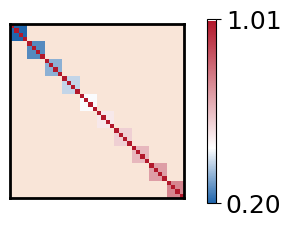

In [15]:
# Block structure
n_blocks = 10
block_size = 4
matrix_size = n_blocks * block_size

# Block mask
mask = np.zeros((matrix_size, matrix_size), dtype=bool)
for i in range(n_blocks):
    start = i * block_size
    end = start + block_size
    mask[start:end, start:end] = True

# Masked matrix
A_masked = np.ma.masked_where(~mask, A)

# Colormap
cmap = LinearSegmentedColormap.from_list(
    "blue_white_red",
    [(0.00, "#2166ac"), (0.3, "white"), (1.00, "#b2182b")]
)

# Plot
fig, ax = plt.subplots(figsize=(3, 3))
ax.set_facecolor('#f9e5d8')
im = ax.imshow(A_masked, cmap=cmap)

ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_linewidth(2)

# Colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.1, shrink=0.68)
cbar.ax.tick_params(labelsize=18)
cbar.set_ticks([A.min(), A.max()])

plt.tight_layout()
plt.show()


## f)

In [16]:
with open("likelihood_data/data_fig2f_1.dat", "r") as f:
    lines = f.readlines()

k = int(lines[0].strip())                    # first line
biomass = np.fromstring(lines[1], sep=' ')   # second line
basin = np.fromstring(lines[2], sep=' ')     # third line
num_list = np.fromstring(lines[3], sep=' ')  # fourth line


## Main paper equation 5 (preediction of likelihood using biomass and mean block size)


In [17]:
def likelihood_block(biomass, basin, num_list, X):
    """
    Compute block likelihood probabilities for a set of states.
    
    Parameters
    ----------
    biomass : array-like
        Biomass of each unique state.
    basin : array-like
        Basin sizes (likelihoods) of each unique state.
    num_list : array-like
        Number of survivors per unique state.
    X : float
        Threshold parameter.
    
    Returns
    -------
    prob_sorted : np.ndarray
        Probabilities of each state being the largest, sorted ascending.
    bio_sorted : np.ndarray
        Biomass values sorted according to probabilities.
    basin_sorted : np.ndarray
        Basin values sorted according to probabilities.
    """
    
    biomass = np.array(biomass, dtype=float)
    basin = np.array(basin, dtype=float)
    num_list = np.array(num_list, dtype=float)
    
    # Replace num_list with mean value (as in original logic)
    num_list = np.array(len(basin) * [np.mean(num_list)])
    
    # Compute means and stds
    a_list = 1 / biomass
    n = len(a_list)
    np.random.seed(42)
    means = (num_list / 2) * (X - a_list)
    stds = np.sqrt(num_list / 12) * (X - a_list)
    
    # -----------------------------
    # Function to compute probability ai is the largest
    def probability_ai_largest(i, means, stds):
        m_i = means[i]
        d_i = stds[i]
        m_others = np.delete(means, i)
        d_others = np.delete(stds, i)
    
        def integrand(x_val):
            pdf_val = stats_norm.pdf(x_val, loc=m_i, scale=d_i)
            cdf_vals = stats_norm.cdf((x_val - m_others) / d_others)
            return pdf_val * np.prod(cdf_vals)
    
        lower_limit = -20 * abs(d_i)
        upper_limit = m_i + 20 * abs(d_i)
        result, _ = quad(integrand, lower_limit, upper_limit, limit=300)
        return result
    
    # -----------------------------
    # Compute probabilities for each variable
    probabilities = np.array([probability_ai_largest(i, means, stds) for i in range(n)])
    
    # Sort by probabilities
    idx = np.argsort(probabilities)  # ascending
    prob_sorted = probabilities[idx]
    bio_sorted = biomass[idx]
    basin_sorted = basin[idx]
    
    return prob_sorted, bio_sorted, basin_sorted


In [18]:
probabilities, biomass_1, basin = likelihood_block(biomass,basin,num_list,1.01)

In [19]:
basin_2 = basin
probabilities_2 = probabilities

### A sixty-species block model (block size six) whose state biomasses resemble those from the previous forty-species case.

In [20]:
with open("likelihood_data/data_fig2f_2.dat", "r") as f:
    lines = f.readlines()

k = int(lines[0].strip())                    # first line
biomass = np.fromstring(lines[1], sep=' ')   # second line
basin = np.fromstring(lines[2], sep=' ')     # third line
num_list = np.fromstring(lines[3], sep=' ')  # fourth line



In [21]:
probabilities, biomass_1, basin = likelihood_block(biomass,basin,num_list,1.01)

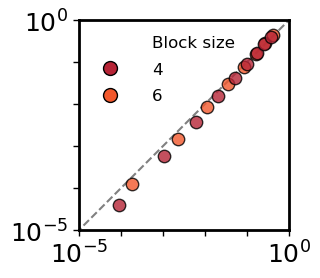

In [22]:
# Plot setup
def custom_formatter(x, pos):
    if np.isclose(x, 1e-5) or np.isclose(x, 1e0):
        return r'$10^{%d}$' % int(np.log10(x))
    else:
        return ''

fig, ax = plt.subplots(figsize=(3, 3))

# Colors
color_2 = '#b62436'
color_6 = '#f2582c'

# Data points
ax.scatter(basin, probabilities, s=80, color=color_6, edgecolor='k', alpha=0.8, zorder=2)
ax.scatter(basin_2, probabilities_2, s=80, color=color_2, edgecolor='k', alpha=0.8, zorder=2)

# Reference line
x = np.logspace(np.log10(1e-6), np.log10(1), 100)
ax.plot(x, x, linestyle='--', color='gray', linewidth=1.5, zorder=1)

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-5, 1)
ax.set_ylim(1e-5, 1)

# Ticks and formatter
ax.xaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0,), numticks=10))
ax.yaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0,), numticks=10))
ax.xaxis.set_major_formatter(FuncFormatter(custom_formatter))
ax.yaxis.set_major_formatter(FuncFormatter(custom_formatter))

# Appearance
ax.tick_params(axis='both', which='major', labelsize=18, width=1, length=4)
for spine in ax.spines.values():
    spine.set_linewidth(2)
    spine.set_color('black')
ax.set_box_aspect(1)
plt.subplots_adjust(left=0.25, right=0.95, bottom=0.2, top=0.95)

# Legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Block size', markersize=0),
    Line2D([0], [0], marker='o', color='w', label='4', markerfacecolor=color_2, markeredgecolor='k', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='6', markerfacecolor=color_6, markeredgecolor='k', markersize=10),
]
ax.legend(handles=legend_elements, loc='upper left', frameon=False, fontsize=12, handletextpad=1.5, labelspacing=0.7)

# Save and show
# plt.savefig('2_d_overlay_colors_updated.svg', dpi=100)
plt.show()


# 3)

## a)

In [23]:
import numpy as np

with open("likelihood_data/data_fig3a_1.dat", "rb") as f:
    data = np.load(f)

    centers_bio = data["centers_bio"]
    emp_mean = data["empirical_mean"]
    emp_sem = data["empirical_sem"]
    th_mean = data["theory_mean"]
    th_sem = data["theory_sem"]

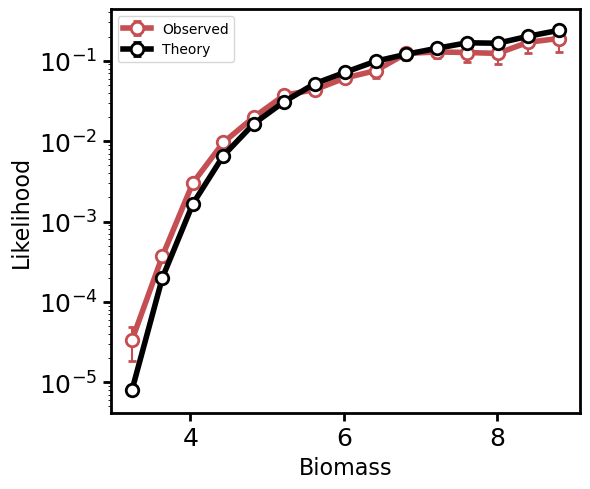

In [24]:
fig, ax = plt.subplots(figsize=(6,5))

ax.errorbar(
    centers_bio,
    emp_mean,
    yerr=emp_sem,
    fmt='o-',
    color='#c44e52',          
    lw=4,
    ms=9,
    mfc='white',
    mec='#c44e52',
    mew=2,
    ecolor='#c44e52',
    elinewidth=1.5,
    capsize=3,
    zorder=2,
    label='Observed'
)


ax.errorbar(
    centers_bio,
    th_mean,
    yerr=th_sem,
    fmt='o-',
    color='black',
    lw=4,
    ms=9,
    mfc='white',
    mec='black',
    mew=2,
    ecolor='black',
    elinewidth=1.5,
    capsize=3,
    zorder=3,
    label='Theory'
)

ax.set_yscale('log')

ax.set_xlabel('Biomass', fontsize=16)
ax.set_ylabel('Likelihood', fontsize=16)

ax.tick_params(axis='both', labelsize=18, width=2, length=6)

for spine in ax.spines.values():
    spine.set_linewidth(2)


ax.legend()


plt.tight_layout()
plt.show()

In [25]:
# Load data
with open("likelihood_data/fig_3a_2.dat", "rb") as f:
    data = np.load(f)

    N_smooth = data["N_smooth"]
    fit_curve = data["fit_curve"]
    Ns_10 = data["Ns_10"]
    curve_10 = data["curve_10"]

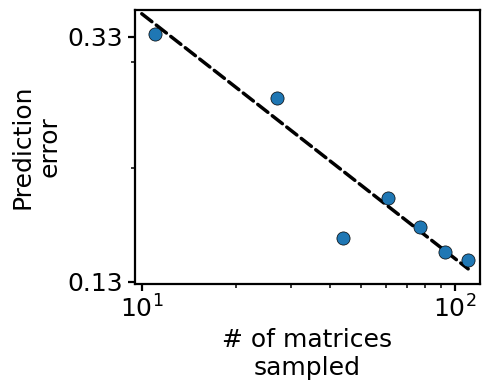

In [26]:

# Figure
fig, ax = plt.subplots(figsize=(5, 4))

# Fitted line
ax.plot(
    N_smooth,
    fit_curve,
    '--',
    color='black',
    linewidth=2.5,
    dash_capstyle='round',
    zorder=1
)

# Scatter
ax.scatter(
    Ns_10,
    curve_10,
    s=90,
    facecolor='#1f77b4',
    edgecolor='black',
    linewidth=0.5,
    zorder=3
)

# Log scales
ax.set_xscale('log')
ax.set_yscale('log')

# Limits
ax.set_xlim(9.5, 120)
ax.set_ylim(0.129, 0.365)

# Labels
ax.set_xlabel('# of matrices\nsampled', fontsize=18)
ax.set_ylabel('Prediction\nerror', fontsize=18)

# ---- Only show labels at 0.13 and 0.33 ----
ax.yaxis.set_major_locator(FixedLocator([0.13, 0.33]))
ax.yaxis.set_major_formatter(FixedFormatter(['0.13', '0.33']))

# Keep minor ticks but remove their labels
ax.yaxis.set_minor_formatter(NullFormatter())

# Tick styling
ax.tick_params(axis='both', which='major',
               labelsize=18, width=1.6, length=5)
ax.tick_params(axis='both', which='minor',
               width=1.1, length=3)

# Frame
for spine in ax.spines.values():
    spine.set_linewidth(1.6)

plt.tight_layout()

plt.show()

## b)

In [27]:
with open("likelihood_data/data_fig3b.dat", "r") as f:
    lines = f.readlines()

k = int(lines[0].strip())                    
biomass = np.fromstring(lines[1], sep=' ')  
basin = np.fromstring(lines[2], sep=' ')    
num_list = np.fromstring(lines[3], sep=' ') 


In [28]:
probabilities, biomass_1, basin_1 = likelihood_block(biomass,basin,num_list,0.5)

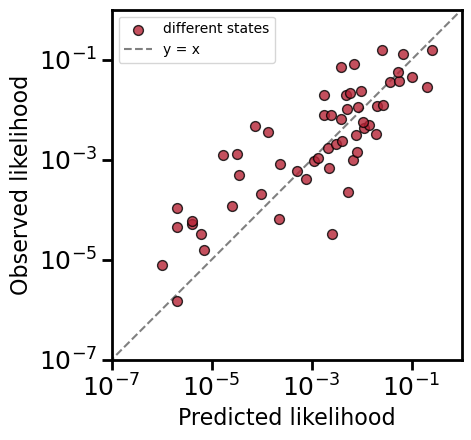

In [29]:
# Plot
fig, ax = plt.subplots(figsize=(5, 5))

# Data points
ax.scatter(basin_1, probabilities, s=50, color='#b62436fd', edgecolor='k', alpha=0.8, zorder=2,label='different states')

# Reference line
x_vals = np.logspace(np.log10(1e-8), np.log10(1), 100)
ax.plot(x_vals, x_vals, linestyle='--', color='gray', linewidth=1.5, zorder=1, label='y = x')

# Scales and limits
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-7, 1)
ax.set_ylim(1e-7, 1)

# Tick and appearance
ax.tick_params(axis='both', which='major', labelsize=18, width=2, length=7)
for spine in ax.spines.values():
    spine.set_linewidth(2)
    spine.set_color('black')
ax.set_box_aspect(1)

# Labels and layout
ax.set_ylabel('Observed likelihood', fontsize=16)
ax.set_xlabel('Predicted likelihood', fontsize=16)
plt.subplots_adjust(left=0.25, right=0.95, bottom=0.2, top=0.95)
plt.legend()
# Show
plt.show()


### We use start_sim to run the simulations. Inside start_sim we can choose which matrix to load and set the output file names.
### Example -- For matrix 'mat_2_mono_10.pkl' using 10,000 initial conditions we can save the unique states in 'raw_unique_1.pkl' and all runs in 'raw_1.pkl'.

In [ ]:
start_sim(10,10000,'likelihood_data/mat_2_mono_10.pkl','likelihood_data/r_2_mono_10.pkl','raw_1.pkl','raw_unique_1.pkl',44)

started


In [ ]:
# Load data
k = 10
with open('raw_unique_1.pkl', 'rb') as file:
    raw_uniue = pickle.load(file)

with open('raw_1.pkl', 'rb') as file:
    raw = pickle.load(file)

# Biomass of each unique state
biomass = []
for i in range(len(raw_uniue[:, 0])):
    biomass.append(sum(raw_uniue[i][k+1:(2*k)+1]))

# Basin sizes
basin = np.zeros(len(biomass))
for element in raw[:, 0]:
    basin[int(element)] += 1

basin = basin / np.sum(basin)

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))


# Scatter plot of biomass vs basin
ax.scatter(biomass, basin, color='#b62436fd', edgecolor='k', alpha=1, zorder=2, s=70,label='different states')

# Log scale for y-axis
ax.set_yscale('log')



# Axis labels
ax.set_xlabel('Biomass', fontsize=18, fontweight='bold', family='Liberation Sans')
ax.set_ylabel('Likelihood', fontsize=18, fontweight='bold', family='Liberation Sans')

# Tick parameters
ax.tick_params(labelsize=18, width=2)

# Thicker spines
for spine in ax.spines.values():
    spine.set_linewidth(2)

# Tight layout
plt.tight_layout()
plt.legend()
plt.ylim(top = 1)
# plt.savefig('2_c_2.svg',dpi = 100)
plt.show()